In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from newsapi import NewsApiClient
from datetime import datetime,timedelta
import warnings
warnings.filterwarnings("ignore")

NEWS_API_KEY = '44cb4d60b0da4138aa1702f6706c65ae'

In [22]:
print(" DOWNLOADING STOCK PRICE DATA")
print("="*60)
tickers=["AAPL", "MSFT", "GOOGL", "AMZN", "TSLA", "NVDA", "META", "JPM", "V", "JNJ"]
end_date = datetime.now() # present date
start_date=datetime.now()-timedelta(days=730)# 2years back
print(f"Date Range: {start_date.date()} to {end_date.date()}")
print("="*60)
tickers_data={}
import os
os.makedirs("../data", exist_ok=True)
for stock in tickers:
    # Flat columns (no ticker level) and include 'Adj Close'
    data=yf.download(stock,start=start_date,end=end_date,auto_adjust=False,multi_level_index=False,progress=False)
    tickers_data[stock]=data
    # Save prices for feature_engineering.ipynb
    data.to_csv(f"../data/{stock}_prices.csv")
    print(f"✅ {stock}: {len(data)} trading days → saved ../data/{stock}_prices.csv")
print("Stocks Downloaded: ",tickers)
print("\n📊 Sample data for AAPL:")
print(tickers_data['AAPL'].head())

 DOWNLOADING STOCK PRICE DATA
Date Range: 2024-10-08 to 2026-10-08


[*********************100%***********************]  1 of 1 completed


✅ AAPL: 501 trading days


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


✅ MSFT: 501 trading days
✅ GOOGL: 501 trading days


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


... (3 outputs left out)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


✅ JPM: 501 trading days
✅ V: 501 trading days


[*********************100%***********************]  1 of 1 completed

✅ JNJ: 501 trading days
Stocks Downloaded:  ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'TSLA', 'NVDA', 'META', 'JPM', 'V', 'JNJ']

📊 Sample data for AAPL:
Price            Close        High         Low        Open    Volume
Ticker            AAPL        AAPL        AAPL        AAPL      AAPL
Date                                                                
2024-10-08  223.897049  224.105298  221.397950  222.439243  31855700
2024-10-09  227.635773  227.844037  222.964854  223.361530  33591100
2024-10-10  227.139908  227.596098  225.285426  225.890366  28183500
2024-10-11  225.662292  227.506863  225.454028  227.397775  31759200
2024-10-14  229.381180  229.807605  226.703582  226.802743  39882100


In [58]:
# Download news headlines using NewsAPI
print("\n DOWNLOADING FINANCIAL NEWS")
print("="*60)
newsapi=NewsApiClient(api_key=NEWS_API_KEY)
def get_stock_news(ticker, days_back=30):
    company_name={
        "AAPL": "Apple",
        "MSFT": "Microsoft",
        "GOOGL": "Google",
        "AMZN": "Amazon",
        "TSLA": "Tesla",
        "NVDA": "Nvidia",
        "META": "Meta Platforms",
        "JPM": "JPMorgan Chase",
        "V": "Visa",
        "JNJ": "Johnson & Johnson"
    }
    company = company_name.get(ticker, ticker)
    end=datetime.now()
    start=end-timedelta(days=days_back)
    print(f"\nFetching news for {company} ({ticker})...")
    print(f"   Date range: {start.date()} to {end.date()}")
    try:
        all_articles=newsapi.get_everything(q=f'{company}',language='en',sort_by='publishedAt',  from_param=start.strftime('%Y-%m-%d'),to=end.strftime('%Y-%m-%d'))
        news_data = []
        for article in all_articles['articles']:
            news_data.append({
                'tickers':ticker,
                'company':company,
                'title': article['title'],
                'description': article['description'],
                'url': article['url'],
                'source':article['source']['name'],
                'publishedAt': article['publishedAt']   
            })
        df=pd.DataFrame(news_data)
        return df

    except Exception as e:
        print(f" Error: {e}")
        return pd.DataFrame()
           


 DOWNLOADING FINANCIAL NEWS


In [67]:
#Collect news for all stocks
stock_news_data={}
for ticker in tickers:
    news_df=get_stock_news(ticker)
    stock_news_data[ticker]=news_df
# Show sample
print("\n📰 Sample headlines for AAPL:")
if len(stock_news_data['AAPL']) > 0:
    print(stock_news_data['AAPL'].head())
else:
    print("⚠️ No news found (API limit might be reached)")
    


Fetching news for Apple (AAPL)...
   Date range: 2026-09-08 to 2026-10-08

Fetching news for Microsoft (MSFT)...
   Date range: 2026-09-08 to 2026-10-08

Fetching news for Google (GOOGL)...
   Date range: 2026-09-08 to 2026-10-08

Fetching news for Amazon (AMZN)...
   Date range: 2026-09-08 to 2026-10-08

Fetching news for Tesla (TSLA)...
   Date range: 2026-09-08 to 2026-10-08

Fetching news for Nvidia (NVDA)...
   Date range: 2026-09-08 to 2026-10-08

Fetching news for Meta Platforms (META)...
   Date range: 2026-09-08 to 2026-10-08

Fetching news for JPMorgan Chase (JPM)...
   Date range: 2026-09-08 to 2026-10-08

Fetching news for Visa (V)...
   Date range: 2026-09-08 to 2026-10-08

Fetching news for Johnson & Johnson (JNJ)...
   Date range: 2026-09-08 to 2026-10-08

📰 Sample headlines for AAPL:
  tickers company                                              title  \
0    AAPL   Apple  Amazon Prime Day 2026 — 60+ of the best tech d...   
1    AAPL   Apple  Microsoft, Nvidia CEOs to

In [73]:
for ticker,df in stock_news_data.items():
    if df.empty:
        print(f" No news found for {ticker} (API limit might be reached)")
    else:
       file_name=f"data/news_{ticker}.csv"
       df.to_csv(file_name,index=False)
       print(f"SAVED data for {ticker}")

SAVED data for AAPL
SAVED data for MSFT
SAVED data for GOOGL
SAVED data for AMZN
SAVED data for TSLA
SAVED data for NVDA
SAVED data for META
SAVED data for JPM
SAVED data for V
SAVED data for JNJ


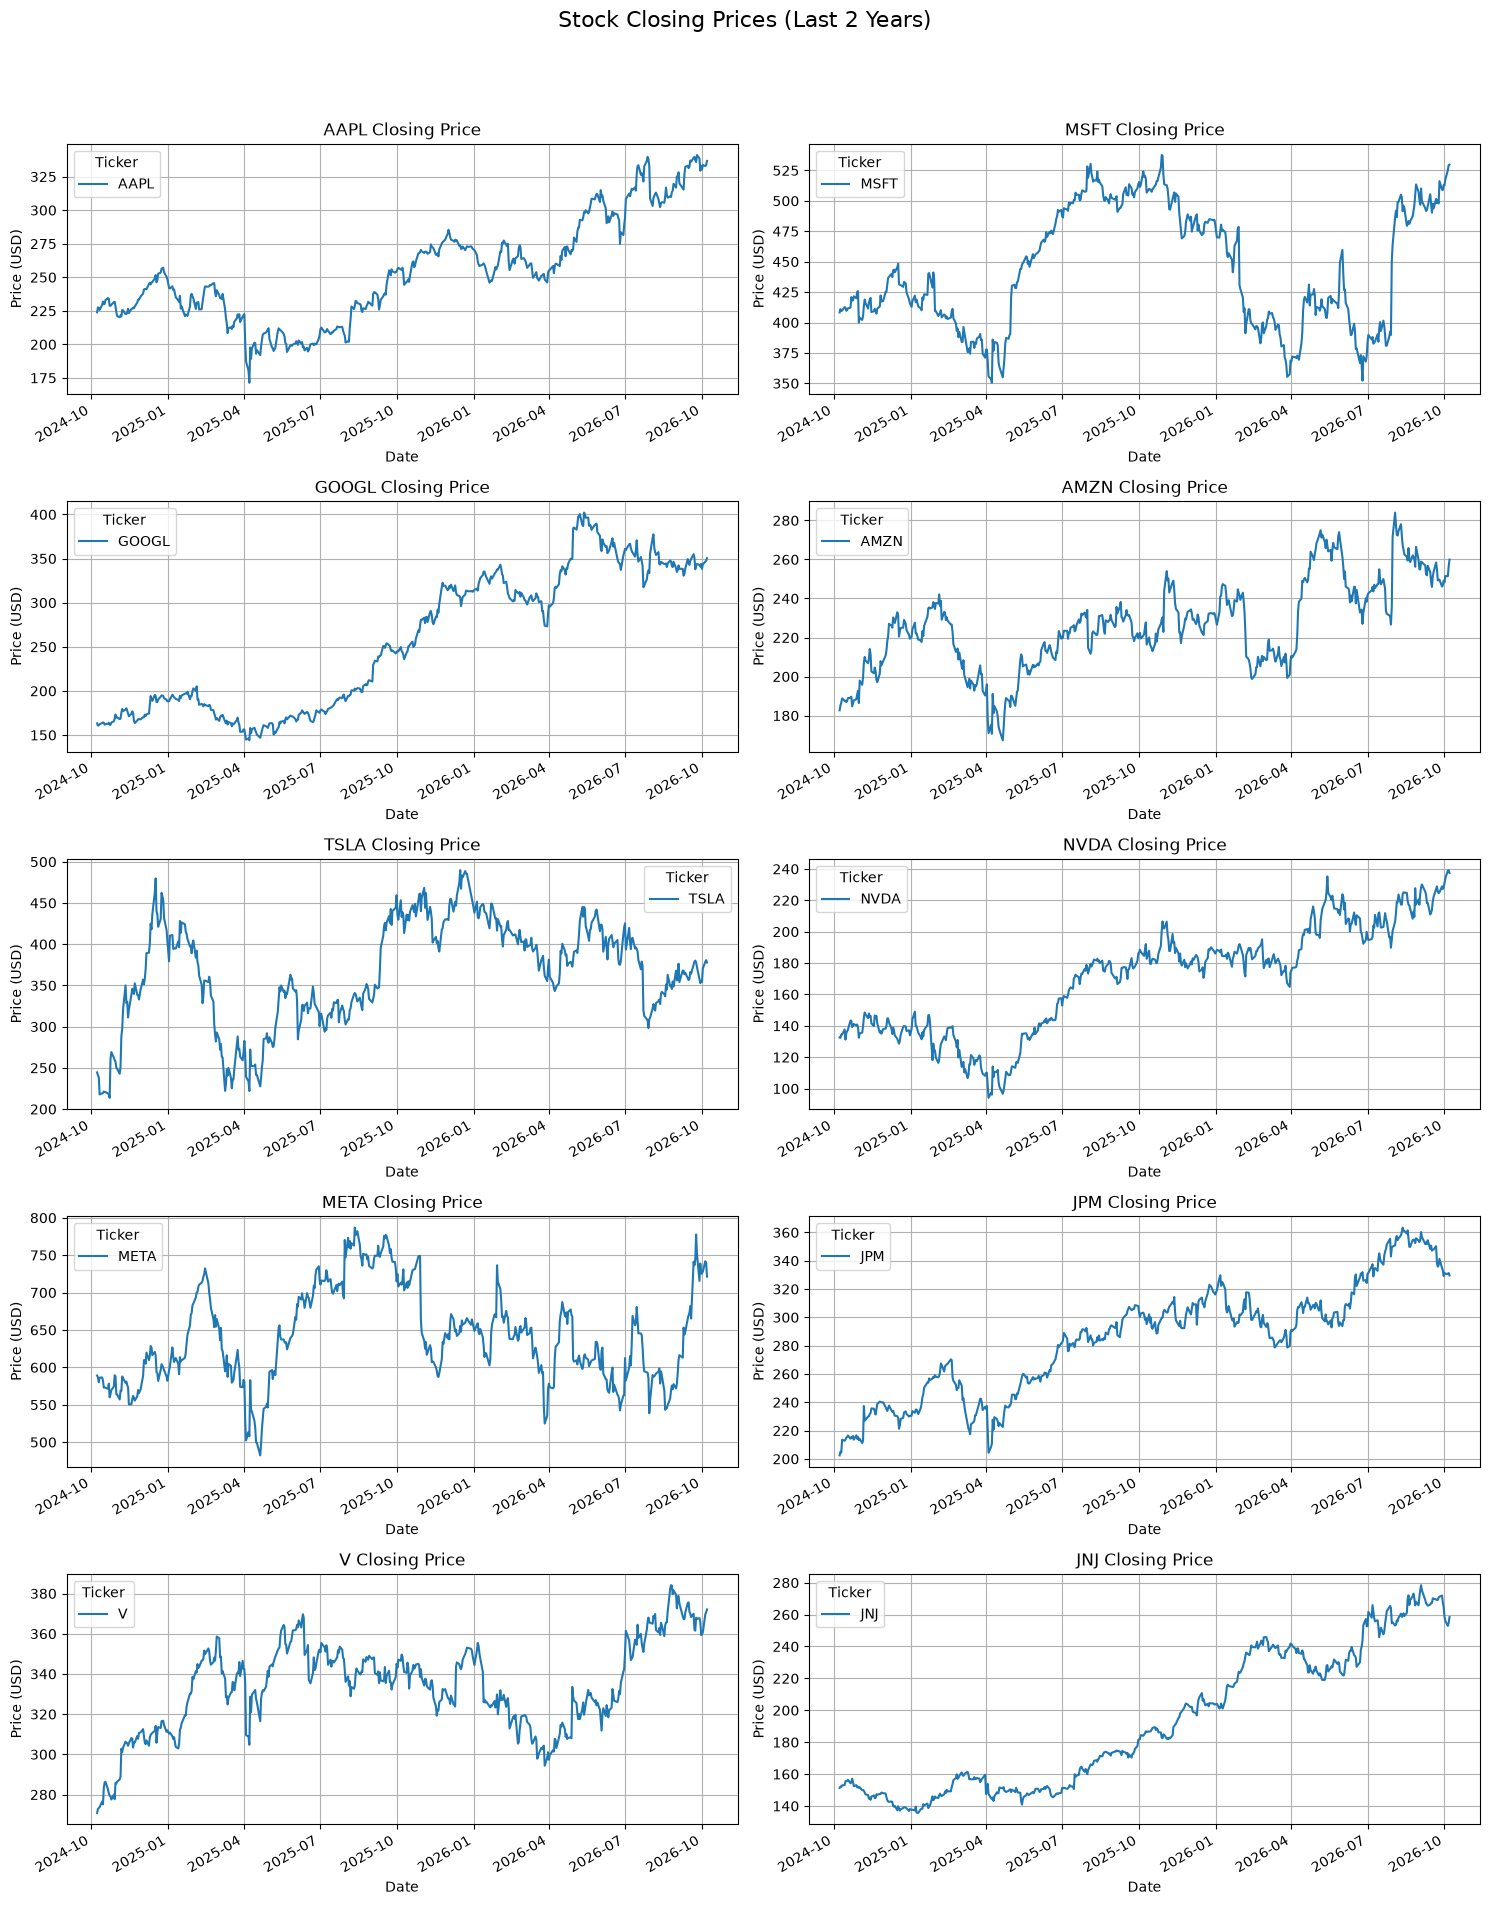

In [77]:
fig,axes=plt.subplots(5,2,figsize=(15,20))
fig.suptitle("Stock Closing Prices (Last 2 Years)",fontsize=16)
for i,ticker in enumerate(tickers):
    ax=axes[i//2,i%2]
    tickers_data[ticker]['Close'].plot(ax=ax)
    ax.set_title(f"{ticker} Closing Price")
    ax.set_xlabel("Date")
    ax.set_ylabel("Price (USD)")
    ax.grid()
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()